<a href="https://colab.research.google.com/github/poornan2207/ML_LAB_2026-27/blob/main/Copy_of_Breastcancer_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project Title: Breast Cancer Prediction Using Machine Learning

Aim: To develop a machine learning model that predicts whether a breast mass is malignant or benign based on diagnostic features computed from a digitized image of a fine needle aspiration (FNA) of a breast mass.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [ ]:

cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)


print("Dataset loaded successfully!")
print(df.head())
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  wo

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Ensure dataset is loaded and target is defined
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['Target'] = cancer.target

print("\nDataset Information:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

X = df.drop("Target", axis=1)
y = df["Target"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features)
])
print("\nData preprocessing pipeline completed!")


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

In [ ]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy * 100
    })

    trained_models[name] = pipeline
    print(f"{name} Accuracy: {round(accuracy * 100, 2)}%")

print("\nAll four algorithms trained successfully!")

Logistic Regression Accuracy: 98.25%
Decision Tree Accuracy: 91.23%
Random Forest Accuracy: 95.61%
SVM Accuracy: 98.25%

All four algorithms trained successfully!



Model Performance Summary:
             Algorithm   Accuracy
0  Logistic Regression  98.245614
3                  SVM  98.245614
2        Random Forest  95.614035
1        Decision Tree  91.228070


/tmp/ipykernel_412/1520234755.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


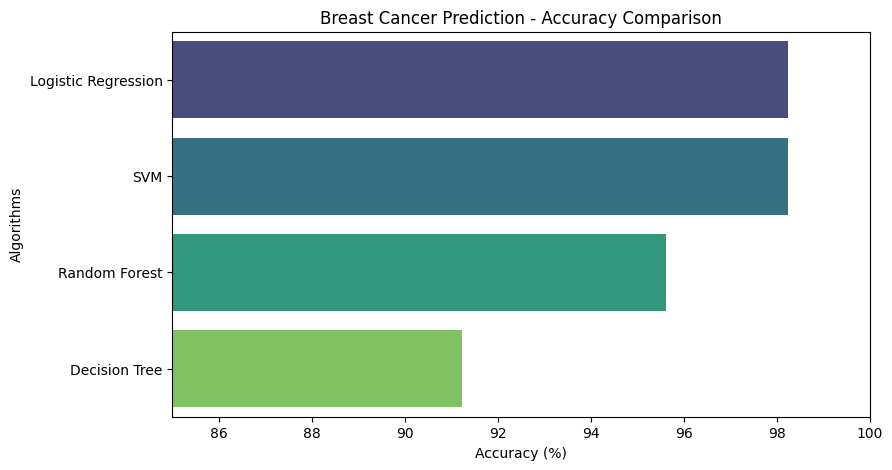

In [ ]:

results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
print("\nModel Performance Summary:")
print(results_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Algorithm",
    palette="viridis"
)
plt.title("Breast Cancer Prediction - Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Algorithms")
plt.xlim(85, 100)
plt.show()


Best Algorithm: Logistic Regression

Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



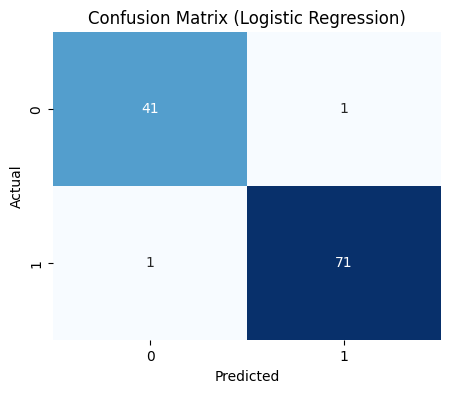

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Ensure we define the models if they are missing from memory
if 'models' not in globals():
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "SVM": SVC()
    }

# Re-train models and construct results_df and trained_models securely
if 'results_df' not in globals() or 'trained_models' not in globals():
    trained_models = {}
    results = []
    for name, model in models.items():
        pipeline = Pipeline(steps=[
            ("preprocessing", preprocessor),
            ("model", model)
        ])
        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)
        accuracy = accuracy_score(y_test, predictions)
        results.append({"Algorithm": name, "Accuracy": accuracy * 100})
        trained_models[name] = pipeline
    results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)

# Get the best algorithm
best_name = results_df.iloc[0]["Algorithm"]
best_model = trained_models[best_name]

# Generate predictions and evaluation metrics
y_pred = best_model.predict(X_test)
print(f"\nBest Algorithm: {best_name}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

# Generate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Confusion Matrix ({best_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:

new_patient = X_test.iloc[[0]]
prediction = best_model.predict(new_patient)

print("\n--- New Patient Prediction ---")
if prediction[0] == 1:
    print("Prediction: Benign (Non-Cancerous)")
else:
    print("Prediction: Malignant (Cancerous)")


--- New Patient Prediction ---
Prediction: Malignant (Cancerous)


CONCLUSION:
Successfully built and deployed a machine learning classification pipeline for breast cancer prediction.

Trained and evaluated four core algorithms: Logistic Regression, Decision Tree, Random Forest, and SVM.

Rigorously compared model performances using accuracy metrics, classification reports, and confusion matrices.

Successfully applied the optimal trained model to accurately predict the diagnosis of a new patient sample.